# NN_L1_cost_threshold

**Expected cost per German credit applicant (UCI cost matrix: a missed bad risk costs 5, a rejected good applicant 1) as a function of the cut-off, out-of-fold predictions of logistic regression, an MLP and XGBoost; cost-optimal cut-off 1/6.**

Neural Networks and Deep Learning (NN), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L1/NN_L1_cost_threshold/NN_L1_cost_threshold.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Lecture 1 of *Neural Networks and Deep Learning*: the chart `cost_threshold` of the slides, recomputed from the public data. Numbers printed with `show()` are the ones on the slide.

cost per applicant, logistic, cut-off 1/6 = 0.554   [german.cost_logit_bayes]
cost per applicant, logistic, cut-off 1/2 = 0.87   [german.cost_logit_05]
cost per applicant, MLP, cut-off 1/6 = 0.568   [german.cost_mlp_bayes]


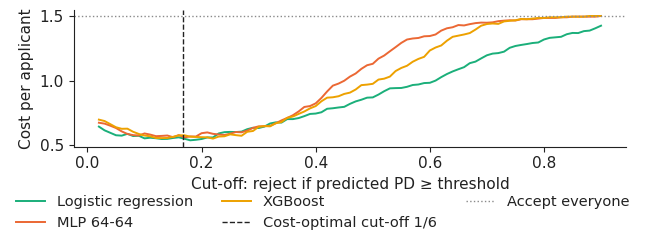

In [3]:
import xgboost as xgb            # import before torch (OpenMP runtimes on macOS)
import torch, torch.nn as nn
torch.set_num_threads(1)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.model_selection import train_test_split, StratifiedKFold
SEED = 20261108

class MLP(nn.Module):
    def __init__(self, d, hidden=(64, 64), act='relu'):
        super().__init__()
        A = {'relu': nn.ReLU, 'tanh': nn.Tanh, 'sigmoid': nn.Sigmoid}[act]
        layers, k = [], d
        for h in hidden:
            layers += [nn.Linear(k, h), A()]; k = h
        layers.append(nn.Linear(k, 1)); self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

def train_mlp(Xtr, ytr, Xva, yva, hidden=(64, 64), act='relu', lr=1e-3, epochs=300, bs=128, patience=25, seed=0):
    """Adam on mini-batches; keeps the weights of the best validation epoch"""
    torch.manual_seed(SEED + seed); rng = np.random.default_rng(SEED + seed)
    m = MLP(Xtr.shape[1], hidden, act); opt = torch.optim.Adam(m.parameters(), lr=lr); lf = nn.BCEWithLogitsLoss()
    Xt, yt = torch.tensor(Xtr), torch.tensor(ytr, dtype=torch.float32).view(-1, 1)
    Xv, yv = torch.tensor(Xva), torch.tensor(yva, dtype=torch.float32).view(-1, 1)
    best, state, bad = np.inf, None, 0
    for ep in range(epochs):
        m.train(); idx = rng.permutation(len(Xt))
        for i in range(0, len(idx), bs):
            b = idx[i:i + bs]; opt.zero_grad(); lf(m(Xt[b]), yt[b]).backward(); opt.step()
        m.eval()
        with torch.no_grad():
            vl = float(lf(m(Xv), yv))
        if vl < best - 1e-5:
            best, bad, state = vl, 0, {k: v.clone() for k, v in m.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    m.load_state_dict(state); m.eval()
    return m

def proba(m, X):
    with torch.no_grad():
        return torch.sigmoid(m(torch.tensor(X))).numpy().ravel()

def xgb_fit(Xtr, ytr, Xva, yva, seed=0):
    m = xgb.XGBClassifier(n_estimators=600, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                          eval_metric='logloss', early_stopping_rounds=50, random_state=SEED + seed, n_jobs=1)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    return m

g = pd.read_csv(DATA + 'german_credit.csv'); yg = g['default'].values.astype(int); Xg = g.drop(columns='default')
def encode_german(tr, others):
    cat = [c for c in tr.columns if tr[c].dtype == object]; num = [c for c in tr.columns if c not in cat]
    levels = {c: sorted(tr[c].unique()) for c in cat}
    def f(d):
        x = d[num].astype(float).copy()
        for c in cat:
            for lv in levels[c][1:]:
                x[f'{c}_{lv}'] = (d[c] == lv).astype(float)
        return x
    xtr = f(tr); mu, sd = xtr.mean(), xtr.std().replace(0, 1)
    return [((xtr - mu) / sd).values.astype(np.float32)] + [((f(o) - mu) / sd).values.astype(np.float32) for o in others]

def german_cv():
    res = {'logit': [], 'mlp': [], 'xgb': []}; oof = {k: np.zeros(len(yg)) for k in res}
    for rep in range(5):
        skf = StratifiedKFold(5, shuffle=True, random_state=SEED + rep)
        for f, (a, b) in enumerate(skf.split(Xg, yg)):
            a_tr, a_va = train_test_split(a, test_size=0.2, stratify=yg[a], random_state=SEED + rep)
            xa, xv, xb = encode_german(Xg.iloc[a_tr], [Xg.iloc[a_va], Xg.iloc[b]])
            pl = LogisticRegression(C=1.0, max_iter=5000).fit(xa, yg[a_tr]).predict_proba(xb)[:, 1]
            pm = proba(train_mlp(xa, yg[a_tr], xv, yg[a_va], hidden=(64, 64), seed=rep * 10 + f, bs=64), xb)
            px = xgb_fit(xa, yg[a_tr], xv, yg[a_va], seed=rep).predict_proba(xb)[:, 1]
            for k, p in (('logit', pl), ('mlp', pm), ('xgb', px)):
                res[k].append(roc_auc_score(yg[b], p))
                if rep == 0:
                    oof[k][b] = p
    return {k: np.array(v) for k, v in res.items()}, oof
A, OOF = german_cv()
cost = lambda p, thr: float((5 * np.sum((p < thr) & (yg == 1)) + np.sum((p >= thr) & (yg == 0))) / len(yg))
thr = np.linspace(0.02, 0.9, 89)
show('german.cost_logit_bayes', 'cost per applicant, logistic, cut-off 1/6', round(cost(OOF['logit'], 1 / 6), 3))
show('german.cost_logit_05', 'cost per applicant, logistic, cut-off 1/2', round(cost(OOF['logit'], 0.5), 3))
show('german.cost_mlp_bayes', 'cost per applicant, MLP, cut-off 1/6', round(cost(OOF['mlp'], 1 / 6), 3))
fig, ax = plt.subplots(figsize=(6.4, 2.5))
for k, c, nm in (('logit', PAL['benchmark'], 'Logistic regression'), ('mlp', PAL['model'], 'MLP 64-64'), ('xgb', PAL['alt'], 'XGBoost')):
    ax.plot(thr, [cost(OOF[k], t) for t in thr], color=c, label=nm)
ax.axvline(1 / 6, color='#222222', lw=1, ls='--', label='Cost-optimal cut-off 1/6')
ax.axhline(5 * yg.mean(), color='#8a8a8a', lw=1, ls=':', label='Accept everyone')
ax.set_xlabel('Cut-off: reject if predicted PD ≥ threshold'); ax.set_ylabel('Cost per applicant')
legend_bottom(fig, ncol=3); fig.tight_layout(rect=(0, 0.14, 1, 1))
fig.savefig('cost_threshold.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()